Training data: (60000, 785)
Testing data: (10000, 785)
Training image shape: (60000, 28, 28, 1)
Testing image shape: (10000, 28, 28, 1)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
MobileNetV2 loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5


c:\study materials\LP-4\solution\.lab\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1688/1688 ━━━━━━━━━━━━━━━━━━━━ 223s 126ms/step - accuracy: 0.8493 - loss: 0.4173 - val_accuracy: 0.8877 - val_loss: 0.3069
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 225s 133ms/step - accuracy: 0.8847 - loss: 0.3142 - val_accuracy: 0.8943 - val_loss: 0.2931
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 175s 104ms/step - accuracy: 0.8940 - loss: 0.2860 - val_accuracy: 0.8990 - val_loss: 0.2798
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 182s 108ms/step - accuracy: 0.9013 - loss: 0.2647 - val_accuracy: 0.9027 - val_loss: 0.2793
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 186s 110ms/step - accuracy: 0.9088 - loss: 0.2474 - val_accuracy: 0.9068 - val_loss: 0.2743
313/313 ━━━━━━━━━━━━━━━━━━━━ 25s 81ms/step - accuracy: 0.9038 - loss: 0.2500
Test Loss: 0.24995656311511993
Test Accuracy: 0.9038000106811523
Epoch 1/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 197s 113ms/step - accuracy: 0.8832 - loss: 0.3222 - val_accuracy: 0.9018 - val_loss: 0.2694
Epoch 2/3
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 214s 127ms/step - accuracy: 0

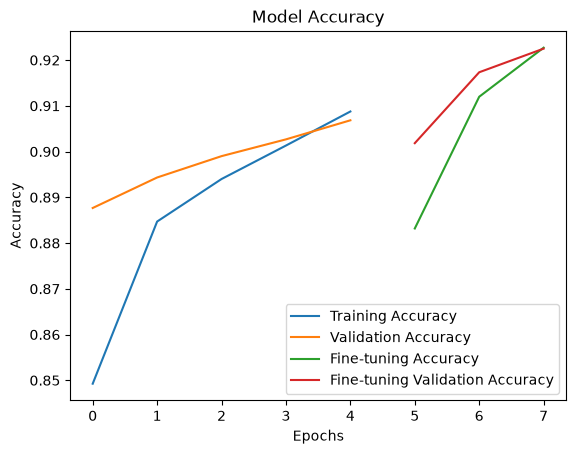

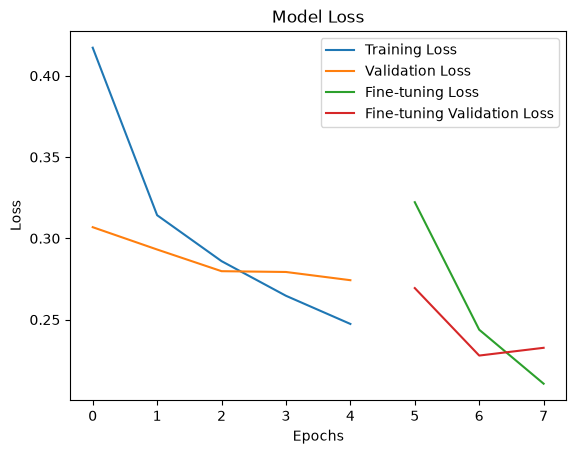

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


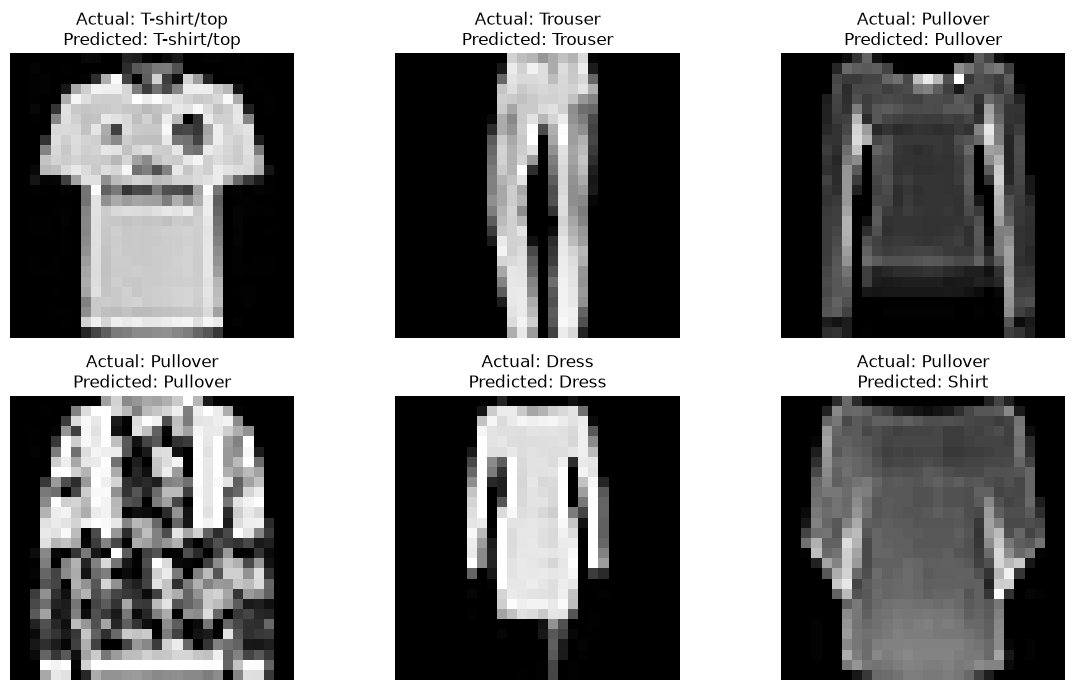

Model saved successfully!


In [1]:

# Practical 5C: Transfer Learning using MobileNetV2
# Fashion MNIST Dataset

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


# STEP 2: Load the local dataset

train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)


# STEP 3: Separate labels and images

# First column contains labels
y_train = train_data.iloc[:, 0].values
y_test = test_data.iloc[:, 0].values

# Remaining columns contain image pixels
x_train = train_data.iloc[:, 1:].values
x_test = test_data.iloc[:, 1:].values


# STEP 4: Reshape images into 28x28 grayscale images

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training image shape:", x_train.shape)
print("Testing image shape:", x_test.shape)


# STEP 5: Split training data into training and validation data

# Shuffle the training data
indices = np.random.permutation(len(x_train))

x_train = x_train[indices]
y_train = y_train[indices]

# Use 10% for validation
split = int(0.1 * len(x_train))

x_val = x_train[:split]
y_val = y_train[:split]

x_train = x_train[split:]
y_train = y_train[split:]


# STEP 6: Preprocess images for MobileNetV2

# MobileNetV2 needs RGB images of size 96x96

def preprocess_image(image, label):

    # Convert grayscale image to RGB
    image = tf.image.grayscale_to_rgb(image)

    # Resize image to 96x96
    image = tf.image.resize(image, (96, 96))

    # Prepare image for MobileNetV2
    image = preprocess_input(image)

    return image, label


# Create TensorFlow datasets

train_dataset = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_dataset = train_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.shuffle(1000).batch(32).prefetch(
    tf.data.AUTOTUNE
)


val_dataset = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
)

val_dataset = val_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(32).prefetch(
    tf.data.AUTOTUNE
)


test_dataset = tf.data.Dataset.from_tensor_slices(
    (x_test, y_test)
)

test_dataset = test_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(32).prefetch(
    tf.data.AUTOTUNE
)


# STEP 7: Load pre-trained MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(96, 96, 3)
)

print("MobileNetV2 loaded successfully!")


# STEP 8: Freeze the base model layers

base_model.trainable = False


# STEP 9: Add custom classification layers

model = models.Sequential([

    layers.Input(shape=(96, 96, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")

])


# STEP 10: Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# STEP 11: Train the model

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)


# STEP 12: Evaluate the model

loss, accuracy = model.evaluate(test_dataset)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


# STEP 13: Fine-tune the model

# Unfreeze the base model
base_model.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


# Compile again with a small learning rate

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# STEP 14: Train the fine-tuned model

fine_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3
)


# STEP 15: Evaluate the fine-tuned model

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Fine-tuned Test Loss:", test_loss)
print("Fine-tuned Test Accuracy:", test_accuracy)


# STEP 16: Plot accuracy

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.plot(
    range(5, 8),
    fine_history.history["accuracy"],
    label="Fine-tuning Accuracy"
)

plt.plot(
    range(5, 8),
    fine_history.history["val_accuracy"],
    label="Fine-tuning Validation Accuracy"
)

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# STEP 17: Plot loss

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.plot(
    range(5, 8),
    fine_history.history["loss"],
    label="Fine-tuning Loss"
)

plt.plot(
    range(5, 8),
    fine_history.history["val_loss"],
    label="Fine-tuning Validation Loss"
)

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


# STEP 18: Visualize predictions

# Fashion MNIST class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


# Take 6 test images
sample_images = x_test[:6]
sample_labels = y_test[:6]

# Prepare images for prediction
images = tf.convert_to_tensor(sample_images)

images = tf.image.grayscale_to_rgb(images)

images = tf.image.resize(images, (96, 96))

images = preprocess_input(images)

# Predict the classes
predictions = model.predict(images)

predicted_labels = np.argmax(predictions, axis=1)


# Display images and predictions

plt.figure(figsize=(12, 7))

for i in range(6):

    plt.subplot(2, 3, i + 1)

    plt.imshow(sample_images[i].squeeze(), cmap="gray")

    actual = class_names[sample_labels[i]]
    predicted = class_names[predicted_labels[i]]

    plt.title(
        "Actual: " + actual +
        "\nPredicted: " + predicted
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# STEP 19: Save the model

model.save("fashion_mnist_transfer_model.keras")

print("Model saved successfully!")
